Clustering Results and Model Performance
---

Staged work for issue #11. `notebooks/taxon_clustering.ipynb` (issue #9) grouped survey events into communities by which coral families were recorded on each one, using k-means on family presence and absence. This notebook asks three questions about those communities: what each one is made of, how well defined they are, and where they occur.

How well defined the communities are is answered two ways. Cluster-quality scores (silhouette) measure how tightly each event sits in its community. A classifier trained to recognize the communities on some areas and tested on areas it has never seen measures whether the communities are consistent enough to be recognized elsewhere, and the features it relies on show which families separate the communities most. That classifier is also where the project's required metrics (accuracy, precision, recall and ROC curves on training, validation and test splits, training time and feature count) are reported. A final check asks whether the communities could instead reflect who collected the data.

Run `taxon_clustering.ipynb` first; this notebook reads its outputs from `data/processed/`.

In [1]:
import time

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    silhouette_samples,
)
from sklearn.model_selection import ParameterGrid, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt

DATA_DIR = Path("../../data")
FIG_DIR = Path("../../figures")
FIG_DIR.mkdir(exist_ok=True)

# Shared palette so every figure (and the poster) uses the same colors.
# Categorical slots are used in this fixed order, never cycled.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
MUTED_GRAY = "#c3c2b7"
INK = "#0b0b0b"
INK_2 = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
LAND = "#e9e8e3"

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "savefig.facecolor": "#fcfcfb",
    "savefig.dpi": 300,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "font.size": 10,
    "text.color": INK,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": MUTED_GRAY,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "xtick.labelcolor": INK_2,
    "ytick.labelcolor": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2,
    "svg.fonttype": "none",
})


def save(fig, name: str) -> None:
    """Save a figure as SVG (vector, for the poster) next to the other project figures."""
    fig.savefig(FIG_DIR / f"{name}.svg", bbox_inches="tight")

import geopandas as gpd

LAND_URL = "https://naciscdn.org/naturalearth/50m/physical/ne_50m_land.zip"
land_path = DATA_DIR / "external" / "ne_50m_land.zip"
if not land_path.exists():
    import requests

    land_path.parent.mkdir(parents=True, exist_ok=True)
    land_path.write_bytes(requests.get(LAND_URL, timeout=120).content)
MAP_EXTENT = (-98.5, -63.0, 16.0, 36.5)  # lon_min, lon_max, lat_min, lat_max
# Clip the world coastline to the study area so saved maps stay small.
land = gpd.read_file(land_path).clip((MAP_EXTENT[0] - 2, MAP_EXTENT[2] - 2, MAP_EXTENT[1] + 2, MAP_EXTENT[3] + 2))


def base_map(ax, extent=MAP_EXTENT):
    """Draw land and set a lat/lon frame with roughly true proportions for the region."""
    land.plot(ax=ax, color=LAND, edgecolor=MUTED_GRAY, linewidth=0.5, zorder=0)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect(1 / np.cos(np.deg2rad((extent[2] + extent[3]) / 2)))
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.grid(False)
    return ax

RANDOM_STATE = 0

## Loading the communities

The clustering notebook exports one row per event with its community label, and the event-by-family presence matrix it clustered. Depth, temperature, region and data provider are not part of the clustering, so they are summarized per event here from the cleaned records: the median depth and temperature of the event's coral records, and its most common region and provider.

In [2]:
processed = DATA_DIR / "processed"
keys = ["survey_id", "event_id"]
events = pd.read_parquet(processed / "taxon_cluster_events.parquet")
presence = pd.read_parquet(processed / "taxon_cluster_family_presence.parquet").set_index(keys)
metrics = pd.read_csv(processed / "taxon_cluster_metrics.csv")
events = events.set_index(keys).loc[presence.index].reset_index()

records = pd.read_parquet(processed / "se_coral_records_cleaned.parquet")
for col in keys:
    records[col] = records[col].astype("string").str.strip()
    events[col] = events[col].astype("string")
mode = lambda s: s.mode().iat[0] if s.notna().any() else None
context = records.groupby(keys).agg(
    depth=("depth", "median"),
    temp=("temp", "median"),
    region=("large_marine_ecosystem", mode),
    provider=("data_provider", mode),
).reset_index()
events = events.merge(context, on=keys, how="left", validate="one_to_one")

X = presence.to_numpy(dtype=float)
communities = sorted(events["cluster"].unique())
print(f"{len(events)} events, {len(communities)} communities, {X.shape[1]} families")
events["cluster"].value_counts().sort_index()

275 events, 2 communities, 43 families


cluster
0    230
1     45
Name: count, dtype: int64

## How the number of communities was chosen

The clustering notebook fit k-means for two to eight communities and kept the count with the highest silhouette. The chart shows that comparison, which is the evidence behind the number of communities used everywhere below.

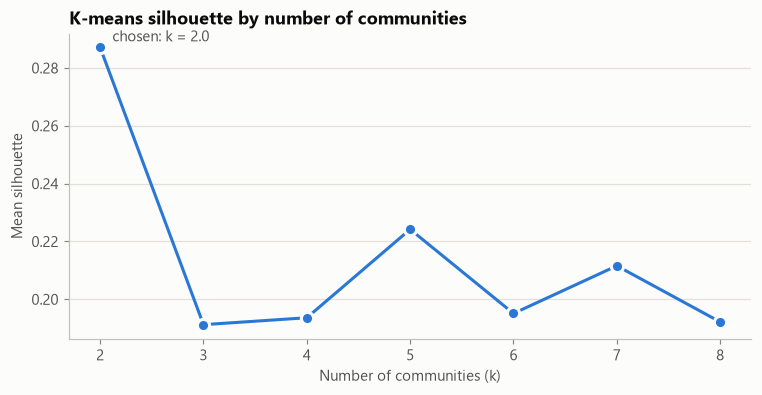

In [3]:
km = metrics[metrics["model"] == "K-Means"].sort_values("k")
chosen = km.loc[km["selected"].astype(bool), "k"].iat[0]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(km["k"], km["silhouette"], color=SERIES[0], marker="o", markersize=8,
        markeredgecolor="#fcfcfb", markeredgewidth=2)
best = km[km["k"] == chosen]
ax.annotate(f"chosen: k = {chosen}", (chosen, best["silhouette"].iat[0]), xytext=(8, 4),
            textcoords="offset points", color=INK_2)
ax.set_xlabel("Number of communities (k)")
ax.set_ylabel("Mean silhouette")
ax.set_xticks(km["k"])
ax.grid(axis="x", visible=False)
ax.set_title("K-means silhouette by number of communities")
save(fig, "results_kmeans_selection")
plt.show()

## Naming the communities

Cluster numbers mean nothing to a reader, so each community is named after the two families that most set it apart: those recorded on a much larger share of its events than on the events of other communities. Records whose family taxonomists have not yet settled ("incertae sedis") are skipped for naming. These are working names generated from the data; our domain lead should review them before they go on the poster.

In [4]:
profile = presence.groupby(events["cluster"].to_numpy()).mean()
names = {}
for c in communities:
    others = profile.drop(index=c).mean()
    named = ~profile.columns.str.contains("incertae sedis")  # families left unplaced by taxonomists
    lift = (profile.loc[c] - others)[(profile.loc[c] >= 0.3) & named].sort_values(ascending=False)
    names[c] = " and ".join(lift.index[:2])

# Order communities by median depth so every chart lists them shallow to deep.
community_order = events.groupby("cluster")["depth"].median().sort_values().index.tolist()
COMMUNITY_COLORS = {c: SERIES[i] for i, c in enumerate(community_order)}
events["community_name"] = events["cluster"].map(names)

pd.DataFrame({
    "name": names,
    "events": events["cluster"].value_counts(),
    "median_depth_m": events.groupby("cluster")["depth"].median(),
    "mean_families_recorded": events.groupby("cluster")["recorded_families"].mean().round(1),
}).loc[community_order]

,name,events,median_depth_m,mean_families_recorded
0,Ellisellidae and Antipathidae,230,94.0,5.2
1,Keratoisididae and Chrysogorgiidae,45,793.0,9.5


## What each community is made of

Because the clustering used presence and absence, a community's composition is the share of its events on which each family was recorded. The chart shows the 14 families recorded most often in any community, with one dot per community.

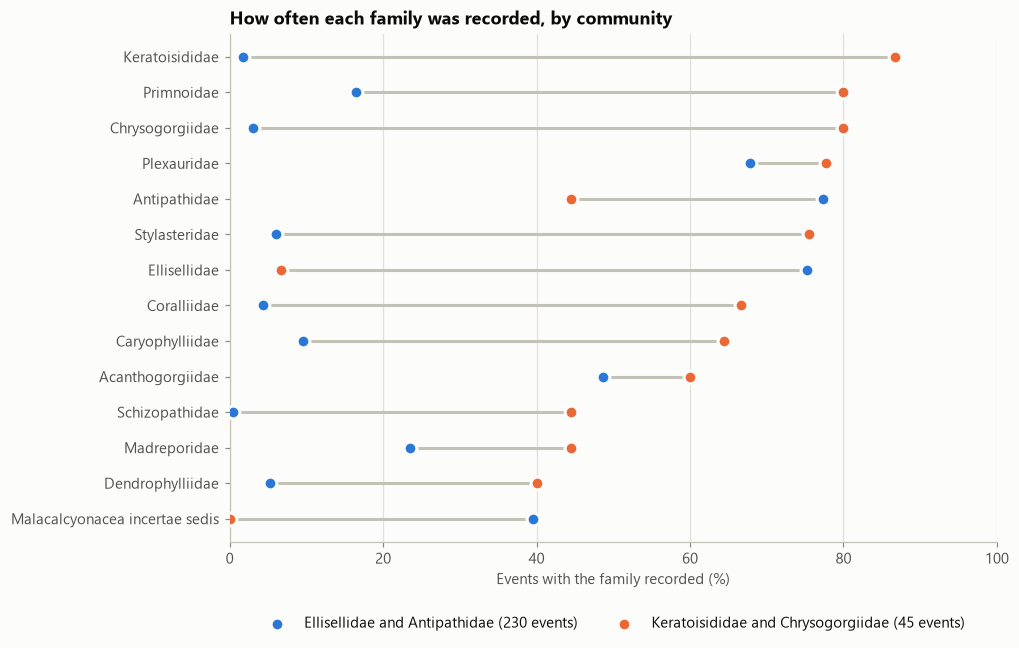

In [5]:
top = profile.max().sort_values(ascending=False).index[:14][::-1]

fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(top))
ax.hlines(yy, profile[top].min() * 100, profile[top].max() * 100, color=MUTED_GRAY, linewidth=2)
for c in community_order:
    ax.scatter(profile.loc[c, top] * 100, yy, s=70, color=COMMUNITY_COLORS[c], edgecolor="#fcfcfb",
               linewidth=2, zorder=3, label=f"{names[c]} ({(events['cluster'] == c).sum()} events)")
ax.set_yticks(yy, top)
ax.set_xlim(0, 100)
ax.set_xlabel("Events with the family recorded (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title("How often each family was recorded, by community")
save(fig, "results_community_composition")
plt.show()

The two communities share few signature families. The larger one, 230 events, is marked by sea whips (Ellisellidae) and black corals (Antipathidae), each recorded on about three quarters of its events, along with plexaurid sea fans. The smaller one, 45 events, is marked by bamboo corals (Keratoisididae), golden corals (Chrysogorgiidae) and primnoid sea fans (Primnoidae), each on about four in five events, plus lace corals (Stylasteridae), precious corals (Coralliidae) and cup corals (Caryophylliidae), which are almost absent from the larger community. Only a few families, such as plexaurid sea fans and black corals, are common in both.

The smaller community also records almost twice as many families per event (9.5 against 5.2). That could be a richer fauna, but it could equally reflect longer dives or more detailed identification, so it should not be read as a difference in diversity without checking survey effort.

## How well defined the communities are: silhouette

The silhouette value of an event compares how close it is to the other events in its community with how close it is to the nearest other community, using the same family-presence features and Euclidean distance the clustering used. Values near 1 mean the event clearly belongs where it is, values near 0 mean it sits on the boundary, and negative values mean it is closer to a different community than its own. The chart sorts every event within its community, so the width of each band shows how much of the community is clearly assigned.

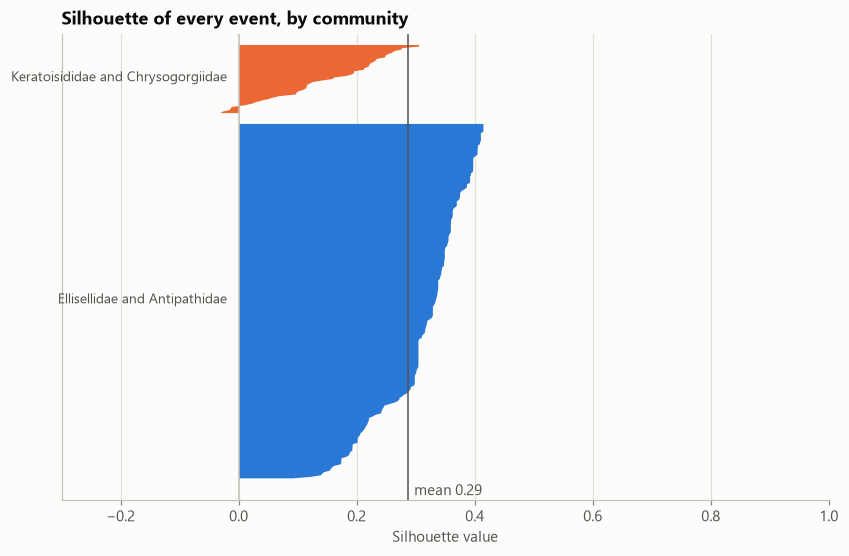

,mean,share_negative
cluster,,
Ellisellidae and Antipathidae,0.31,0.00
Keratoisididae and Chrysogorgiidae,0.15,0.11


In [6]:
sil = pd.Series(silhouette_samples(X, events["cluster"]), index=events.index)

fig, ax = plt.subplots(figsize=(9, 5.5))
y_start = 0
for c in community_order:
    values = np.sort(sil[events["cluster"] == c].to_numpy())
    ax.fill_betweenx(np.arange(y_start, y_start + len(values)), 0, values,
                     color=COMMUNITY_COLORS[c], linewidth=0)
    ax.text(-0.02, y_start + len(values) / 2, names[c], ha="right", va="center", color=INK_2, fontsize=9)
    y_start += len(values) + 6
ax.axvline(sil.mean(), color=INK_2, linewidth=1)
ax.annotate(f"mean {sil.mean():.2f}", (sil.mean(), -4), xytext=(4, 0),
            textcoords="offset points", color=INK_2, va="top")
ax.set_ylim(-14, y_start)
ax.axvline(0, color=MUTED_GRAY, linewidth=1)
ax.set_yticks([])
ax.set_xlabel("Silhouette value")
ax.grid(axis="y", visible=False)
ax.set_xlim(min(-0.3, sil.min() - 0.05), 1)
ax.set_title("Silhouette of every event, by community")
save(fig, "results_silhouette")
plt.show()

summary = sil.groupby(events["cluster"]).agg(mean="mean", share_negative=lambda s: (s < 0).mean())
summary.index = summary.index.map(names)
summary.round(2)

The same picture in two dimensions: the first two principal components of the family-presence matrix, with one panel per community. Each panel highlights one community against all the others in gray, which keeps every community readable even where they overlap.

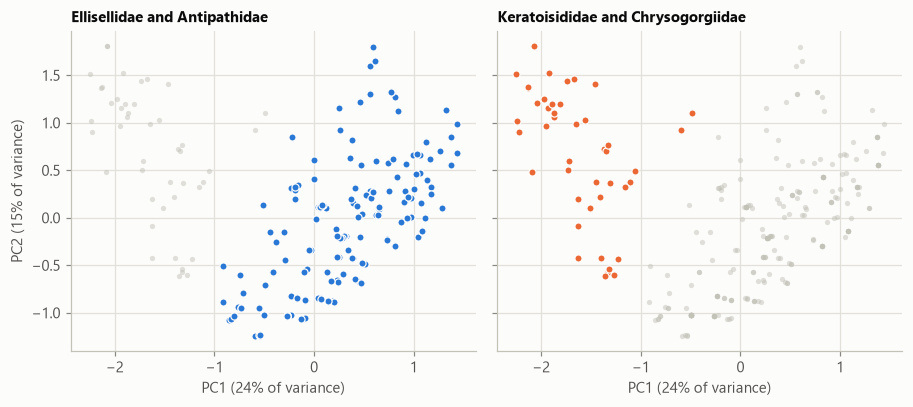

In [7]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pc = pd.DataFrame(pca.fit_transform(X), columns=["PC1", "PC2"], index=events.index)
fig, axes = plt.subplots(1, len(community_order), figsize=(4.2 * len(community_order), 3.8),
                         sharex=True, sharey=True, squeeze=False)
for ax, c in zip(axes[0], community_order):
    mask = events["cluster"] == c
    ax.scatter(pc.loc[~mask, "PC1"], pc.loc[~mask, "PC2"], s=12, color=MUTED_GRAY, alpha=0.5, linewidth=0)
    ax.scatter(pc.loc[mask, "PC1"], pc.loc[mask, "PC2"], s=22, color=COMMUNITY_COLORS[c],
               edgecolor="#fcfcfb", linewidth=0.8)
    ax.set_title(names[c], fontsize=10)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
axes[0, 0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
fig.tight_layout()
save(fig, "results_pca_by_community")
plt.show()

## How well defined the communities are: can they be recognized in new areas?

A silhouette score only describes the events that were clustered. A stronger test of whether the communities are real is whether a model that learns them in some areas can recognize them in areas it has never seen. If the communities were arbitrary slices of a continuum, a model would do little better than guessing the most common community on new ground.

### Splitting by area, not at random

Events close together on the seafloor are near-copies of each other: the same habitat, often the same species. A random split would put near-identical events in both training and test sets, and the test score would mostly measure memory. Instead, each event is assigned to a block of 0.5° latitude by 0.5° longitude (about 55 km on a side, far wider than any dive), and whole blocks are held out: some blocks for training, some for validation (used to choose model settings) and some for the final test.

Blocks are very uneven in size, so a single shuffle of blocks can produce lopsided parts. The split below is chosen from 100 shuffles as the one closest to 60% training, 20% validation and 20% test in which every community has at least two events in each part. That choice uses only the sizes and labels of the parts, never any model's score, so it does not leak test information into the model.

In [8]:
BLOCK_DEG = 0.5  # block size in degrees (about 55 km)
blocks = (np.floor(events["lat"] / BLOCK_DEG).astype(int).astype(str) + "_"
          + np.floor(events["lon"] / BLOCK_DEG).astype(int).astype(str))
y = events["cluster"].to_numpy()

def block_split(seed: int) -> dict[str, np.ndarray]:
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    trainval_idx, test_idx = next(outer.split(X, y, blocks))
    inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=seed)
    train_sub, val_sub = next(inner.split(X[trainval_idx], y[trainval_idx], blocks.iloc[trainval_idx]))
    return {"Training": trainval_idx[train_sub], "Validation": trainval_idx[val_sub], "Test": test_idx}


def split_quality(split: dict[str, np.ndarray]) -> float:
    """Distance from a 60/20/20 split; infinite if any community has fewer than 2 events in a part."""
    if any(np.bincount(y[idx], minlength=y.max() + 1).min() < 2 for idx in split.values()):
        return np.inf
    sizes = np.array([len(idx) for idx in split.values()]) / len(y)
    return float(np.abs(sizes - [0.6, 0.2, 0.2]).sum())


best_seed = min(range(100), key=lambda s: split_quality(block_split(s)))
splits = block_split(best_seed)
train_idx, val_idx, test_idx = splits.values()
events["split"] = ""
for name, idx in splits.items():
    events.iloc[idx, events.columns.get_loc("split")] = name

assert not set(blocks.iloc[train_idx]) & set(blocks.iloc[test_idx]), "a block is in both training and test"
print(f"{blocks.nunique()} blocks; split seed {best_seed}; "
      + ", ".join(f"{k} {len(v)} ({len(v) / len(y):.0%})" for k, v in splits.items()))
pd.crosstab(events["cluster"].map(names), events["split"]).loc[[names[c] for c in community_order], list(splits)]

60 blocks; split seed 0; Training 177 (64%), Validation 49 (18%), Test 49 (18%)


split,Training,Validation,Test
cluster,,,
Ellisellidae and Antipathidae,150,40,40
Keratoisididae and Chrysogorgiidae,27,9,9


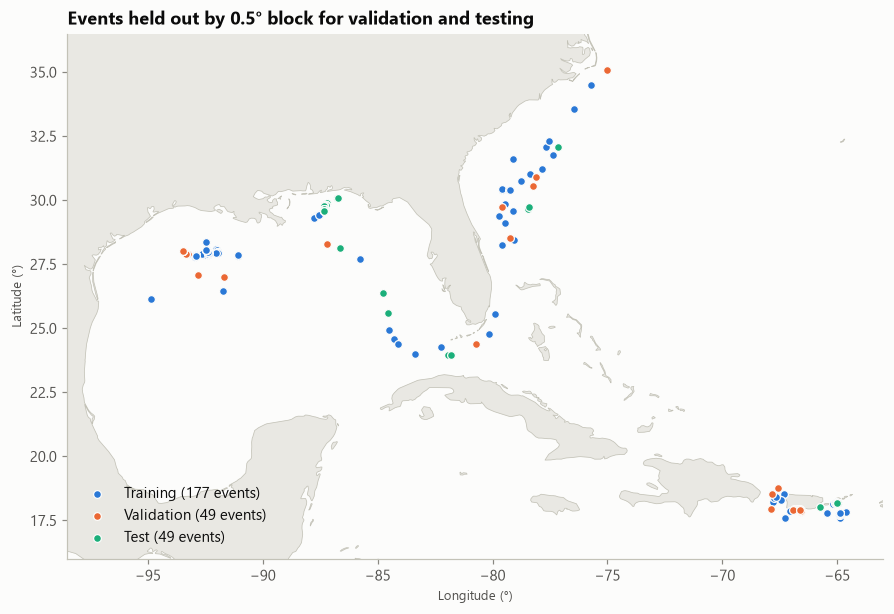

In [9]:
fig, ax = plt.subplots(figsize=(10, 6.2))
base_map(ax)
for i, name in enumerate(splits):
    sub = events[events["split"] == name]
    ax.scatter(sub["lon"], sub["lat"], s=26, color=SERIES[i], edgecolor="#fcfcfb", linewidth=0.8,
               label=f"{name} ({len(sub)} events)", zorder=2)
ax.legend(loc="lower left")
ax.set_title("Events held out by 0.5° block for validation and testing")
save(fig, "results_split_map")
plt.show()

### Models

Two classifiers are compared. Logistic regression is the simple baseline: it draws straight boundaries between communities, so if it does well the communities are separated in a simple way. A random forest can capture interactions between families (for example, a community marked by one family only when another is absent). The features are the same family-presence columns the clustering used, scaled for logistic regression inside a pipeline so the scaler is fit on training data only. Each model's settings are chosen by macro-averaged F1 on the validation set, which weights every community equally regardless of its size.

In [10]:
def positive_scores(model, idx):
    """Class probabilities in the shape roc_auc_score expects (one column when there are two classes)."""
    proba = model.predict_proba(X[idx])
    return proba[:, 1] if proba.shape[1] == 2 else proba


def evaluate(model, idx) -> dict:
    pred = model.predict(X[idx])
    return {
        "accuracy": accuracy_score(y[idx], pred),
        "precision_macro": precision_score(y[idx], pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y[idx], pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y[idx], pred, average="macro", zero_division=0),
        "roc_auc_macro": roc_auc_score(y[idx], positive_scores(model, idx), multi_class="ovr",
                                       average="macro", labels=model.classes_),
    }


model_specs = {
    "Logistic regression": (
        lambda **p: make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, **p)),
        {"C": [0.01, 0.1, 1, 10]},
    ),
    "Random forest": (
        lambda **p: RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, **p),
        {"max_depth": [None, 4, 8], "min_samples_leaf": [1, 3, 5]},
    ),
}

tuning_rows, models, results = [], {}, []
for name, (make, grid) in model_specs.items():
    best = None
    for params in ParameterGrid(grid):
        model = make(**params).fit(X[train_idx], y[train_idx])
        val_f1 = f1_score(y[val_idx], model.predict(X[val_idx]), average="macro")
        tuning_rows.append({"model": name, "params": str(params), "val_f1_macro": val_f1})
        if best is None or val_f1 > best[0]:
            best = (val_f1, params)

    start = time.perf_counter()
    models[name] = make(**best[1]).fit(X[train_idx], y[train_idx])
    duration = time.perf_counter() - start
    for split, idx in splits.items():
        results.append({"model": name, "split": split, **evaluate(models[name], idx),
                        "train_seconds": duration, "n_features": X.shape[1], "params": str(best[1])})

results = pd.DataFrame(results)
results.pivot(index="model", columns="split", values=["accuracy", "precision_macro", "recall_macro", "roc_auc_macro"]).round(3)

accuracy                     precision_macro           \
split                   Test Training Validation            Test Training   
model                                                                       
Logistic regression     0.98    0.994        1.0           0.988    0.997   
Random forest           1.00    1.000        1.0           1.000    1.000   

                               recall_macro                     roc_auc_macro  \
split               Validation         Test Training Validation          Test   
model                                                                           
Logistic regression        1.0        0.944    0.981        1.0           1.0   
Random forest              1.0        1.000    1.000        1.0           1.0   

                                         
split               Training Validation  
model                                    
Logistic regression      1.0        1.0  
Random forest            1.0        1.0

In [11]:
results.groupby("model")[["params", "train_seconds", "n_features"]].first()

,params,train_seconds,n_features
model,,,
Logistic regression,{'C': 0.1},0.004924,43
Random forest,"{'max_depth': None, 'min_samples_leaf': 1}",0.608090,43


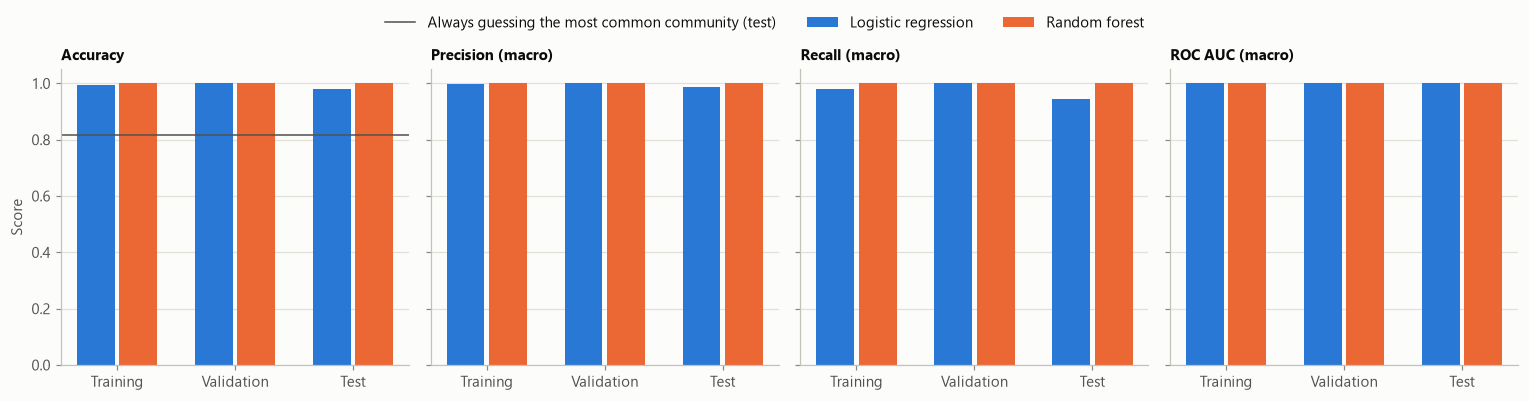

In [12]:
metric_labels = {"accuracy": "Accuracy", "precision_macro": "Precision (macro)",
                 "recall_macro": "Recall (macro)", "roc_auc_macro": "ROC AUC (macro)"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
model_names = list(models)
x = np.arange(len(splits))
width = 0.36
for ax, (col, label) in zip(axes, metric_labels.items()):
    for i, m in enumerate(model_names):
        vals = results[results["model"] == m].set_index("split").loc[list(splits), col]
        ax.bar(x + (i - 0.5) * width, vals, width=width - 0.04, color=SERIES[i], label=m)
    ax.set_xticks(x, list(splits))
    ax.set_title(label, fontsize=10)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="x", visible=False)
majority = pd.Series(y[test_idx]).value_counts(normalize=True).iloc[0]
axes[0].axhline(majority, color=INK_2, linewidth=1, label="Always guessing the most common community (test)")
axes[0].set_ylabel("Score")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
save(fig, "results_classifier_metrics")
plt.show()

### ROC curves

An ROC curve shows the trade-off between catching events that belong to a community (true positive rate) and wrongly flagging events that do not (false positive rate) as the model's confidence threshold moves. A curve hugging the top-left corner is ideal and the diagonal is random guessing. The area under the curve (AUC) summarizes it: 1.0 is perfect and 0.5 is chance. With two communities a single curve per split is enough, since the curve for the other community is its mirror image; with more, there is one curve per community. Curves are shown for whichever model scored the higher macro F1 on validation.

Model with the best validation macro F1: Logistic regression


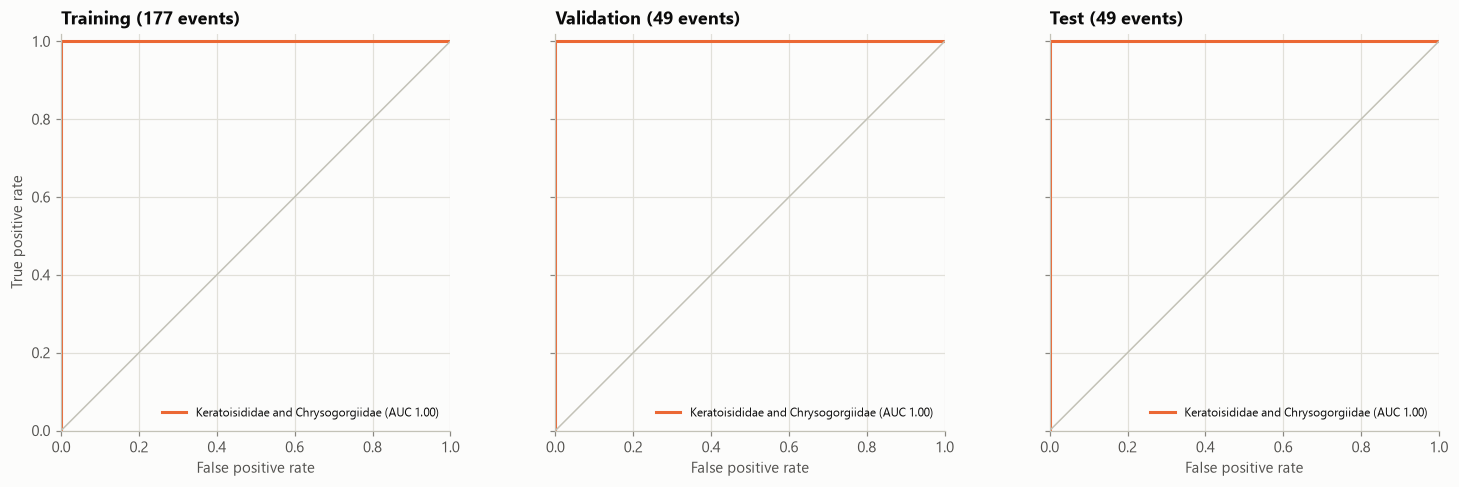

In [13]:
final_name = results[results["split"] == "Validation"].set_index("model")["f1_macro"].idxmax()
final_model = models[final_name]
print(f"Model with the best validation macro F1: {final_name}")

smallest = events["cluster"].value_counts().idxmin()
curve_communities = community_order if len(communities) > 2 else [smallest]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for ax, (split, idx) in zip(axes, splits.items()):
    proba = final_model.predict_proba(X[idx])
    for c in curve_communities:
        k = list(final_model.classes_).index(c)
        truth = y[idx] == c
        if truth.all() or not truth.any():
            continue
        fpr, tpr, _ = roc_curve(truth, proba[:, k])
        ax.plot(fpr, tpr, color=COMMUNITY_COLORS[c], label=f"{names[c]} (AUC {roc_auc_score(truth, proba[:, k]):.2f})")
    ax.plot([0, 1], [0, 1], color=MUTED_GRAY, linewidth=1)
    ax.set(xlabel="False positive rate", title=f"{split} ({len(idx)} events)", xlim=(0, 1), ylim=(0, 1.02))
    ax.set_aspect("equal")
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("True positive rate")
fig.tight_layout()
save(fig, "results_roc_curves")
plt.show()

### Where the model makes mistakes

The confusion matrix shows, for the held-out test areas, how often events of each community were recognized correctly (the diagonal) and which communities they were confused with.

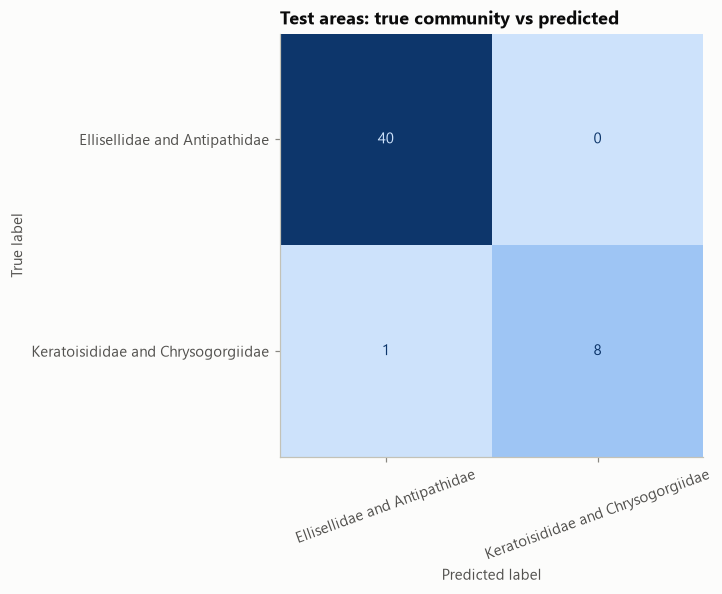

                                    precision    recall  f1-score   support

     Ellisellidae and Antipathidae       0.98      1.00      0.99        40
Keratoisididae and Chrysogorgiidae       1.00      0.89      0.94         9

                          accuracy                           0.98        49
                         macro avg       0.99      0.94      0.96        49
                      weighted avg       0.98      0.98      0.98        49



In [14]:
test_pred = final_model.predict(X[test_idx])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    pd.Series(y[test_idx]).map(names), pd.Series(test_pred).map(names),
    labels=[names[c] for c in community_order], cmap=mpl.colors.ListedColormap(SEQ_BLUE),
    colorbar=False, ax=ax, xticks_rotation=20,
)
ax.grid(False)
ax.set_title("Test areas: true community vs predicted")
save(fig, "results_confusion_matrix")
plt.show()

print(classification_report(y[test_idx], test_pred, labels=community_order,
                            target_names=[names[c] for c in community_order], zero_division=0))

## Which families distinguish the communities

Permutation importance measures how much the model's test score drops when one family's presence column is shuffled, breaking its link to the community. A large drop means the model relies on that family to tell communities apart. It is computed on the held-out test areas so it reflects what generalizes, not what the model memorized.

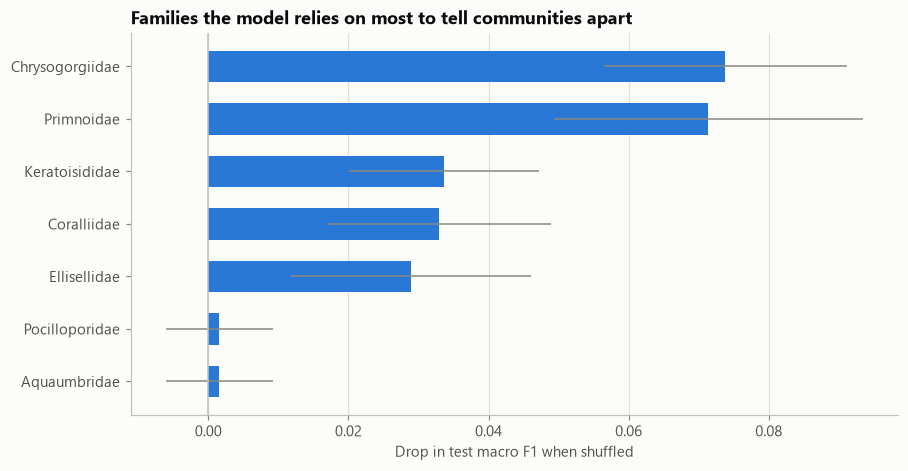

In [15]:
perm = permutation_importance(final_model, X[test_idx], y[test_idx], scoring="f1_macro",
                              n_repeats=50, random_state=RANDOM_STATE)
importance = pd.DataFrame({"family": presence.columns, "mean": perm.importances_mean, "std": perm.importances_std})
importance = importance[importance["mean"] > 0].sort_values("mean").tail(8)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(importance["family"], importance["mean"], xerr=importance["std"], color=SERIES[0], height=0.6,
        error_kw={"ecolor": INK_MUTED, "elinewidth": 1})
ax.axvline(0, color=MUTED_GRAY, linewidth=1)
ax.set_xlabel("Drop in test macro F1 when shuffled")
ax.grid(axis="y", visible=False)
ax.set_title("Families the model relies on most to tell communities apart")
save(fig, "results_feature_importance")
plt.show()

## Where the communities live

Each map highlights one community against all clustered events in gray.

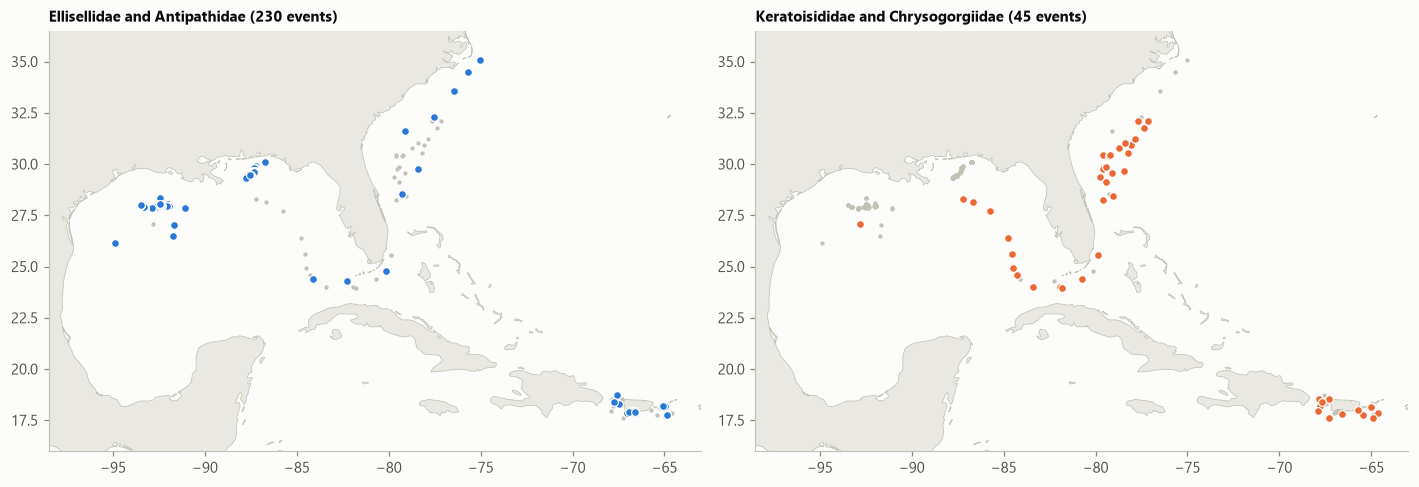

region,Caribbean Sea,Gulf of Mexico,Southeast U.S. Continental Shelf
cluster,,,
Ellisellidae and Antipathidae,62,161,7
Keratoisididae and Chrysogorgiidae,15,9,21


In [16]:
ncols = min(3, len(community_order))
nrows = -(-len(community_order) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 4.6 * nrows), squeeze=False)
axes = axes.ravel()
for ax, c in zip(axes, community_order):
    base_map(ax)
    ax.scatter(events["lon"], events["lat"], s=8, color=MUTED_GRAY, linewidth=0, zorder=1)
    sub = events[events["cluster"] == c]
    ax.scatter(sub["lon"], sub["lat"], s=26, color=COMMUNITY_COLORS[c], edgecolor="#fcfcfb", linewidth=0.8, zorder=2)
    ax.set_title(f"{names[c]} ({len(sub)} events)", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes[len(community_order):]:
    ax.set_visible(False)
fig.tight_layout()
save(fig, "results_community_maps")
plt.show()

pd.crosstab(events["cluster"].map(names), events["region"]).loc[[names[c] for c in community_order]]

## The environment of each community

The communities were formed from composition alone, with no environmental information. Comparing their depth and temperature afterwards is a first look at the project's central question: if communities sit in distinct environmental conditions, environmental factors should be able to predict them. Each dot is an event and the black line is the community's median.

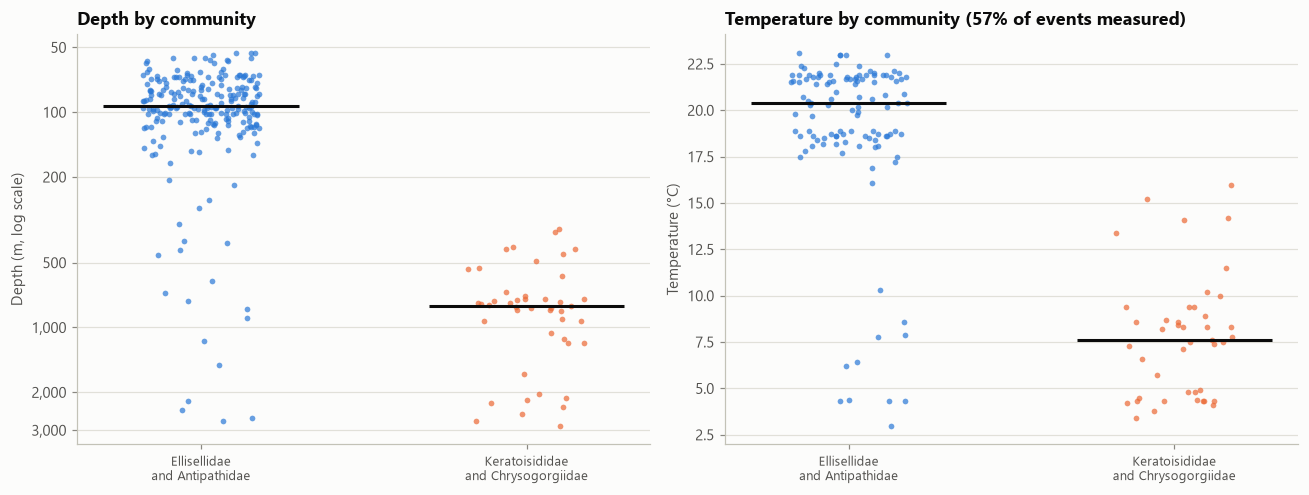

,depth,temp,lat
cluster,,,
Ellisellidae and Antipathidae,94.0,20.4,28.1
Keratoisididae and Chrysogorgiidae,793.0,7.6,27.7


In [17]:
env = [("depth", "Depth (m, log scale)", True), ("temp", "Temperature (°C)", False)]
rng = np.random.default_rng(RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (col, label, log) in zip(axes, env):
    for i, c in enumerate(community_order):
        values = events.loc[events["cluster"] == c, col].dropna()
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(values)), values, s=14,
                   color=COMMUNITY_COLORS[c], alpha=0.7, linewidth=0)
        ax.hlines(values.median(), i - 0.3, i + 0.3, color=INK, linewidth=2)
    ax.set_xticks(range(len(community_order)), [names[c].replace(" and ", "\nand ") for c in community_order],
                  fontsize=8.5)
    ax.set_ylabel(label)
    ax.grid(axis="x", visible=False)
    if log:
        ax.set_yscale("log")
        ticks = [50, 100, 200, 500, 1000, 2000, 3000]
        ax.yaxis.set_major_locator(mpl.ticker.FixedLocator(ticks))
        ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
        ax.invert_yaxis()
axes[0].set_title("Depth by community")
axes[1].set_title(f"Temperature by community ({events['temp'].notna().mean():.0%} of events measured)")
fig.tight_layout()
save(fig, "results_environment_by_community")
plt.show()

env_summary = events.groupby("cluster")[["depth", "temp", "lat"]].median().round(1)
env_summary.index = env_summary.index.map(names)
env_summary.loc[[names[c] for c in community_order]]

## Could the communities reflect who collected the data?

Different programs survey different places and depths with different cameras and identification practices. If a community is made up almost entirely of one program's events, it may describe that program rather than the seafloor. The chart shows each community's events by data provider, and Cramér's V summarizes the association (0 means no link between community and provider, 1 means each provider's events fall in a single community).

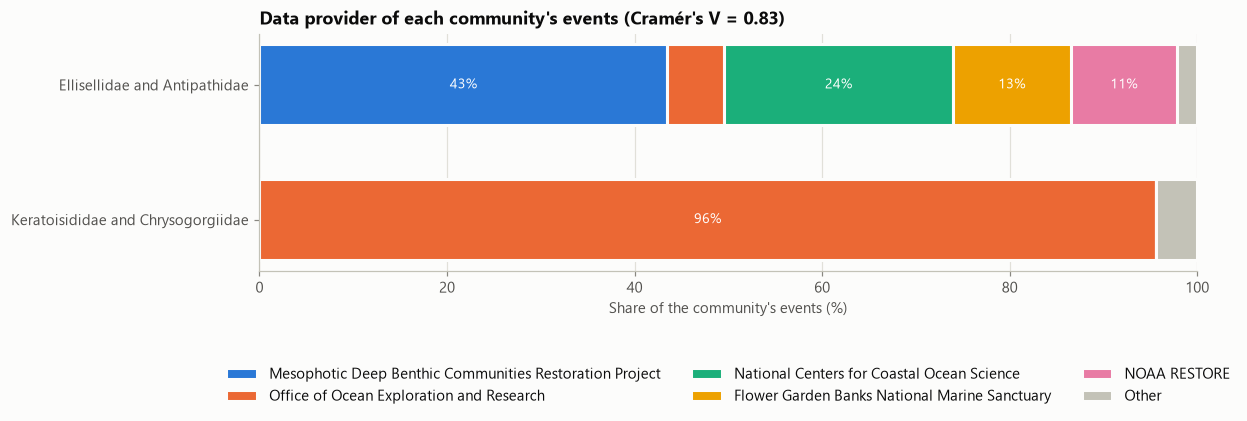

Events deeper than 500 m: 49; providers: {'NOAA, Office of Ocean Exploration and Research': 43, 'Smithsonian Institution, National Museum of Natural History': 6}


In [18]:
def cramers_v(a, b) -> float:
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table)[0]
    return float(np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))))


short = events["provider"].fillna("Unknown").str.replace("NOAA, ", "").str.replace(" Program", "")
minor = short.value_counts()[lambda s: s < 10].index
short = short.where(~short.isin(minor), "Other")
providers = short.value_counts().drop("Other", errors="ignore").index.tolist() + (["Other"] if "Other" in set(short) else [])
mix = pd.crosstab(events["cluster"], short, normalize="index").loc[community_order, providers] * 100
provider_colors = {p: (MUTED_GRAY if p == "Other" else SERIES[i]) for i, p in enumerate(providers)}

fig, ax = plt.subplots(figsize=(11, 1.2 + 0.8 * len(community_order)))
left = np.zeros(len(mix))
yy = np.arange(len(mix))
for p in providers:
    values = mix[p].to_numpy()
    ax.barh(yy, values, left=left, color=provider_colors[p], height=0.6, edgecolor="#fcfcfb", linewidth=2, label=p)
    for yi, (l, v) in enumerate(zip(left, values)):
        if v >= 8:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += values
ax.set_yticks(yy, [names[c] for c in community_order])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of the community's events (%)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.35))
v_provider = cramers_v(events["cluster"], short)
ax.set_title(f"Data provider of each community's events (Cramér's V = {v_provider:.2f})")
save(fig, "results_provider_by_community")
plt.show()

deep = events["depth"] > 500
print(f"Events deeper than 500 m: {deep.sum()}; providers: {events.loc[deep, 'provider'].value_counts().to_dict()}")

This is the main caveat on these communities. The deep-family community is 96% Ocean Exploration and Research events, while the shallow community is spread across four programs (Cramér's V = 0.83). The reason is that Ocean Exploration and Research is almost the only program that dives below the mesophotic zone in this dataset: of the 49 events deeper than 500 m, 43 are theirs and the other 6 are Smithsonian collections. In this data, deep water and one program's dives are therefore the same set of events, and no analysis of this dataset alone can say how much of the split is ecology and how much is one program's camera, dive plan and identification practice.

The depth split itself is ecologically plausible, since bamboo, golden and precious corals are known deep-water families. But any later model that predicts these labels from depth will look excellent for a reason that has little to do with the communities, which matters for how the project's central question is answered.

## Summary

K-means on family presence divided the 275 events into two communities: a shallow one at a median of 94 m and about 20 °C, marked by sea whips and black corals and found mostly on the northern Gulf reefs and around Puerto Rico, and a deep one at a median of 793 m and under 8 °C, marked by bamboo, golden and primnoid corals and found along the Southeast slope, the Florida Straits and the Caribbean. Two communities scored the highest silhouette of the counts tried, but at 0.29 the structure is moderate, and the deep community is loosely held together (mean silhouette 0.15, with about one event in nine closer to the shallow community).

The communities are easy to recognize in new areas. Trained on 177 events and tested on 49 events in areas it never saw, logistic regression assigned 98% of test events correctly, with macro precision 0.99, macro recall 0.94 and ROC AUC 1.0; the random forest was perfect on the test set. Always guessing the shallow community would already score 82%, so the useful number is recall on the deep community, 8 of 9 test events. Both models trained in under a second on 43 features. The families they rely on are the deep-water markers: golden corals, primnoid sea fans, bamboo corals and precious corals.

The near-perfect scores say less than they seem to. With two communities this different, a single deep-water family is almost enough to tell them apart. More importantly, the deep community is essentially the Ocean Exploration and Research program's dives, because that program is almost the only one working below 500 m in this dataset. The split is consistent with a real mesophotic versus deep-sea difference, but this data cannot separate that from a difference between programs. For the project's central question, these labels would make depth look like a near-perfect predictor. A more informative next step is to cluster the mesophotic events on their own, where four programs overlap and the communities, if they exist, are not confounded with who collected them.